In [6]:
import sys
import os
import json
import numpy as np
import scipy as sp

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../mouse-control/src'))
from utils_mouse_control import read_utils as read_utils_control

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils
from utils import analysis_utils
from models import model_utils

In [7]:
import importlib
importlib.reload(read_utils)
importlib.reload(read_utils_control)
importlib.reload(analysis_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
# file_ids = list(range(0, 12+1))
file_ids = [2]

organism = 'mouse'
model_variant = 'ss'

In [5]:
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

# scores

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
scores_per_shuffle = list()
for shuffle_id in range(100):
	scores_per_dataset = list()
	for filename in filenames:
		((bom_spn, _, _, _, _, _, _),
		 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(read_utils_control.get_model_path(shuffle_id), filename, model_variant, manual=False)
		scores_per_dataset.append((bom_spn, hgm_spn))
	bom_spns, hgm_spns = zip(*scores_per_dataset)
	scores_per_shuffle.append([bom_spns, hgm_spns])

neuron_scores_per_shuffle = [assemble(*scores_per_shuffle[i]) for i in range(100)]
scores_per_shuffle = None

In [8]:
scores_per_dataset_actual = list()
for filename in filenames:
	((bom_spn, _, _, _, _, _, _),
	 (hgm_spn, _, _, _, _, _, _)) = analysis_utils.read_scores(read_utils.get_model_path(), filename, model_variant, manual=False)
	scores_per_dataset_actual.append((bom_spn, hgm_spn))
bom_spns_actual, hgm_spns_actual = zip(*scores_per_dataset_actual)

neuron_scores_actual = assemble(bom_spns_actual, hgm_spns_actual)
scores_per_dataset_actual = None

In [ ]:
plot_utils.plot_performance_plot(
	neuron_scores_actual, None,
	title='scores for all neurons', limits=(-0.5, 0.1, -0.3, 0.05), force_medians=False
)

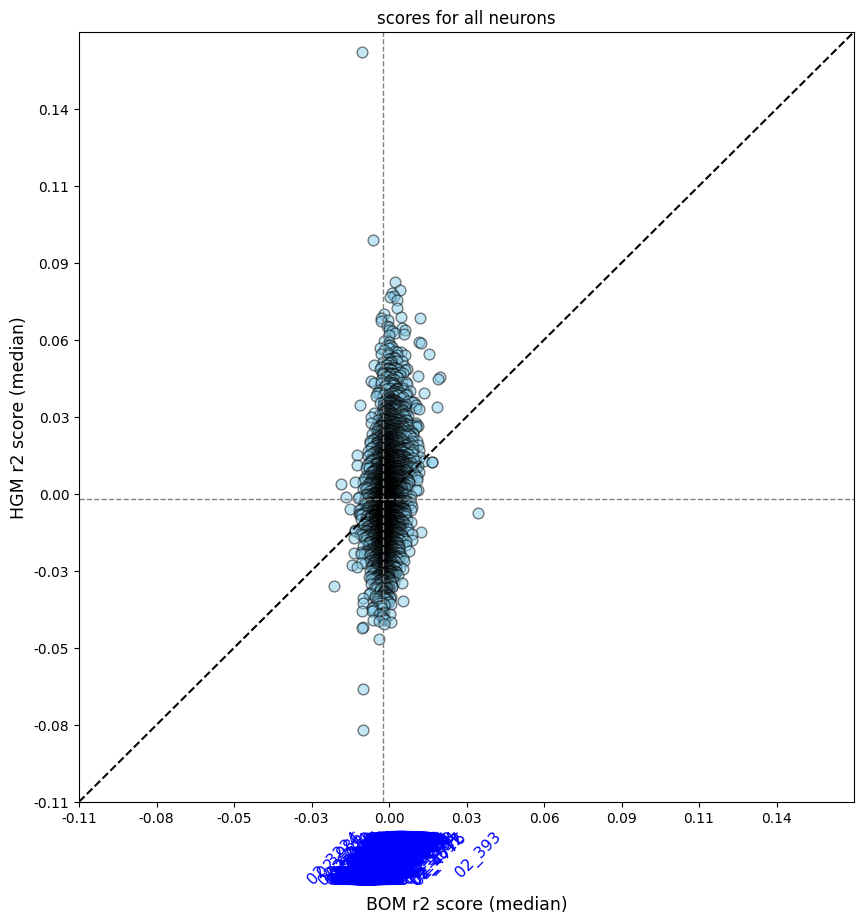

In [10]:
plot_utils.plot_performance_plot(
	neuron_scores_per_shuffle[0], None,
	title='scores for all neurons', limits=(-0.5, 0.1, -0.3, 0.05), force_medians=False
)